In [56]:
import pandas as pd
import matplotlib.pyplot as plt

In [57]:
udf = pd.read_csv('Universities.csv', index_col='Univ')
udf.head()

,SAT,Top10,Accept,SFRatio,Expenses,GradRate
Univ,,,,,,
Brown,1310,89,22,13,22704,94
CalTech,1415,100,25,6,63575,81
CMU,1260,62,59,9,25026,72
Columbia,1310,76,24,12,31510,88
Cornell,1280,83,33,13,21864,90


In [58]:
from sklearn.preprocessing import MinMaxScaler

In [59]:
scaler = MinMaxScaler()
scaled_df = scaler.fit_transform(udf)

In [60]:
from sklearn.cluster import AgglomerativeClustering


In [61]:
model = AgglomerativeClustering(n_clusters=3,linkage='complete')
model.fit(scaled_df)

AgglomerativeClustering(linkage='complete', n_clusters=3)

In [62]:
model.labels_

array([0, 2, 0, 0, 0, 2, 2, 0, 2, 2, 2, 0, 0, 1, 2, 1, 2, 1, 0, 2, 0, 0,
       0, 1, 2])

In [63]:
udf['label'] = model.labels_

In [64]:
udf.head()

,SAT,Top10,Accept,SFRatio,Expenses,GradRate,label
Univ,,,,,,,
Brown,1310,89,22,13,22704,94,0
CalTech,1415,100,25,6,63575,81,2
CMU,1260,62,59,9,25026,72,0
Columbia,1310,76,24,12,31510,88,0
Cornell,1280,83,33,13,21864,90,0


In [65]:
from sklearn.metrics import silhouette_score


In [66]:
silhouette_score(scaled_df, udf['label'])

np.float64(0.29296263039983844)

In [67]:
grp = udf.groupby('label')

In [68]:
for x,y in grp:
    print(y)
    print('_'*60)

               SAT  Top10  Accept  SFRatio  Expenses  GradRate  label
Univ                                                                 
Brown         1310     89      22       13     22704        94      0
CMU           1260     62      59        9     25026        72      0
Columbia      1310     76      24       12     31510        88      0
Cornell       1280     83      33       13     21864        90      0
Georgetown    1255     74      24       12     20126        92      0
Northwestern  1260     85      39       11     28052        89      0
NotreDame     1255     81      42       13     15122        94      0
UCBerkeley    1240     95      40       17     15140        78      0
UMichigan     1180     65      68       16     15470        85      0
UPenn         1285     80      36       11     27553        90      0
UVA           1225     77      44       14     13349        92      0
____________________________________________________________
             SAT  Top10  Acce

In [69]:
grp.agg('mean')

,SAT,Top10,Accept,SFRatio,Expenses,GradRate
label,,,,,,
0,1260.0,78.818182,39.181818,12.818182,21446.909091,87.636364
1,1061.5,38.750000,70.000000,19.250000,9953.000000,71.750000
2,1355.5,89.000000,26.900000,10.000000,40897.200000,91.700000


In [70]:
from scipy.cluster import hierarchy


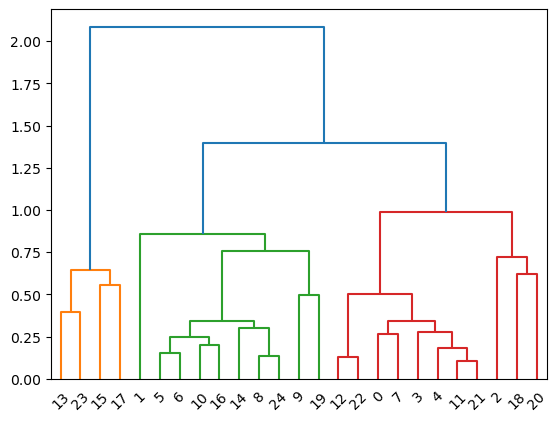

In [71]:
hr = hierarchy.linkage(scaled_df, method='complete')
dh = hierarchy.dendrogram(hr,color_threshold=1.25)

In [72]:
from sklearn.metrics import silhouette_score

In [73]:
silhouette_score(scaled_df, model.labels_)

np.float64(0.29296263039983844)